## **Source Model Accuracy with Errors**

In [1]:
from pathlib import Path
from typing import Any, Literal

import numpy as np
from numpy.typing import NDArray
import matplotlib as mpl
import matplotlib.pyplot as plt

from bloodmoon.io import simulation_files
from bloodmoon.mask import CodedMaskCamera, codedmask
from bloodmoon.mask import count, decode, variance
from bloodmoon.optim import model_shadowgram
import darksun as ds

from IROSrec.handle import config_dirpaths
import imgmaker as mgm

plt.rcdefaults()

RCPARAMS = {
    'axes.formatter.limits': (-3, 3),
    'savefig.bbox': 'tight',
}
mpl.rcParams.update(RCPARAMS)

In [2]:
MASK_FITS: str = "mask_NTHT_20260129_CORRECTED.fits"
UPS_X, UPS_Y = 2, 1

SKYFIELD: str = "IROSDummy"
DATA_FITS: str = "baseline_2-50keV_1ks"

RUN_ID: str = 'Crab_rec_1ks_2-50keV'
E_min, E_max = 2.0, 50.0           # [keV]

hide_bulk_els_y: float = 1.5       # [mm] 

ID_CAMERA: str = 'cam1a'
# ID_CAMERA: str = 'cam1b'

In [3]:
from darksun.data import DataLoader, CatalogueLoader, Log

def extract_cam_data(
    camID: str,
    dl_path: str,
    cl_path: str,
    src_db_path: str,
    **dl_kws,
) -> tuple[DataLoader, CatalogueLoader, Log]:
    sdl_cam = ds.get_data(dl_path, **dl_kws)
    cat_cam = ds.get_catalogue(cl_path)
    _idx = 0 if camID[-1] == 'a' else 1
    log_cam = ds.load_database(src_db_path)[_idx]
    return sdl_cam, cat_cam, log_cam


MASK_PATH, SIMUL_DATA_PATH, SAVE_PATH = config_dirpaths(
    mask=MASK_FITS,
    skyfield=SKYFIELD,
    simul=DATA_FITS,
    runID=RUN_ID,
)
OUT_RESULTS_PATH = mgm.config_savedata_to()
wfm: CodedMaskCamera = codedmask(MASK_PATH, UPS_X, UPS_Y, hide_bulk_els_y=hide_bulk_els_y)
filepaths: dict[str, dict[str, Path]] = simulation_files(SIMUL_DATA_PATH)

sdl_cam, cat_cam, log_cam = extract_cam_data(
    camID=ID_CAMERA,
    dl_path=filepaths[ID_CAMERA]["reconstructed"],
    cl_path=filepaths[ID_CAMERA]["sources"],
    src_db_path=f"{SAVE_PATH}/IROS_sources_db.fits",
    E_min=E_min,
    E_max=E_max,
)

# Loading data...
# Loading completed!


CATALOG ='IROS_benchmark_catalogue_1ks.fits' / Catalog file                      [astropy.io.fits.card]


In [4]:
detector, _ = count(wfm, sdl_cam.DLdata)
varmap = variance(wfm, detector)
true_sky = decode(wfm, detector)

UserInfo: using bulk mask of [0.0 x 1.5] mm.


In [5]:
from bloodmoon.images import argmax

def find_boxmax(sky: NDArray, centre: tuple[int, int], boxsize: int = 5) -> tuple[int, int]:
    """Finds the argmax of given sky in a box centered around `pos`."""
    rcut, ccut = map(lambda idx: slice(idx - boxsize, idx + boxsize + 1), centre)
    p, q = centre
    n, m = argmax(sky[rcut, ccut])
    return p - boxsize + n, q - boxsize + m


IDX: int = 0
print(f'Analysing source {log_cam.log['ID'][IDX].upper()} from cam {ID_CAMERA.upper()}')

SRC_DATA = {
    'sx': log_cam.log['shift_x'][IDX],
    'sy': log_cam.log['shift_y'][IDX],
    'cts': log_cam.log['fluence'][IDX],
    'pos': find_boxmax(true_sky, (log_cam.log['y'][IDX], log_cam.log['x'][IDX])),
    'crp': (36, 4),
}

sg_model = model_shadowgram(wfm, SRC_DATA['sx'], SRC_DATA['sy']) * SRC_DATA['cts']
sky_model = decode(wfm, sg_model)
var_model = variance(wfm, sg_model)

get_cropped = lambda x: ds.crop(x, SRC_DATA['pos'], SRC_DATA['crp'])
psf_true, psf_var = map(get_cropped, (true_sky, varmap))
psf_model, psf_model_var = map(get_cropped, (sky_model, var_model))

Analysing source S17 from cam CAM1A


In [25]:
def set_phase(x: NDArray) -> NDArray:
    """Centers `x` values around zero."""
    return np.arange(len(x) + 1) - len(x) // 2 - 0.5

def get_slices(*arrs: NDArray) -> tuple[tuple[NDArray, ...], tuple[NDArray, ...]]:
    n, m = arrs[0].shape
    xslice, yslice = zip(*tuple((c[(n - 1) // 2, :], c[:, (m - 1) // 2]) for c in arrs))
    return xslice, yslice

def get_plot_data(
    psf: NDArray,
    psf_err: NDArray,
    modelled: NDArray,
    modelled_err: NDArray,
    mode: str,
) -> tuple[NDArray, NDArray, str]:
    if mode == 'ratio':
        sigma = psf_err / np.abs(modelled) + np.abs(psf / np.square(modelled)) * modelled_err
        return psf / modelled - 1, sigma, 'ratio - 1'

    res = psf - modelled
    sigma = np.sqrt(np.square(psf_err) + np.square(modelled_err))

    if mode == 'res':
        return res, sigma, 'residues [ph]'

    return res / sigma, np.zeros_like(res), 'residues [$\\sigma$]'


def show_SPSF(
    camera: CodedMaskCamera,
    true_w_err: tuple[NDArray, NDArray],
    modelled_w_err: tuple[NDArray, NDArray],
    mode: Literal['res', 'ratio', 'sigma'],
    save_to: str | None = None,
    save_options: dict[str, Any] | None = None,
    **fig_kws,
) -> None:
    """
    Plots the SPSF heat maps and profiles along fine/coarse axes + cfr with modelled source.
    """
    dtx, dty = ds.pixels_angular_resolution(camera, verbose=False)

    if mode not in ('res', 'ratio', 'sigma'):
        raise ValueError(f"Invalid input mode '{mode}'.")
    
    psf, modelled = true_w_err[0], modelled_w_err[0]
    psf_xslice, psf_yslice = get_slices(*true_w_err)
    modelled_xslice, modelled_yslice = get_slices(*modelled_w_err)

    xres, xsigma, lbl = get_plot_data(*psf_xslice, *modelled_xslice, mode)
    yres, ysigma, _ = get_plot_data(*psf_yslice, *modelled_yslice, mode)

    slice_clrs = ('OrangeRed', 'DodgerBlue')
    errbar_factory = dict(
        linestyle='',
        elinewidth=0.7,
        capsize=0,
    )
    res_subtitle = 'Residues' if mode in ('res', 'sigma') else 'Ratio'

    # plot figure
    fig, axs = plt.subplots(2, 3, tight_layout=True, **fig_kws)
    axs = axs.flatten()
    
    # ------------------------ SPFS HEAT MAPS ------------------------
    img_layout = {'origin': 'lower', 'interpolation': 'none', 'aspect': 2 * psf.shape[1] / psf.shape[0]}

    axs[0].set_title('Crab SPFS')
    psf_img = axs[0].imshow(psf, cmap='gist_heat', **img_layout)
    cbar = fig.colorbar(psf_img, ax=axs[0], location='right', shrink=0.8, pad=0.05)
    cbar.set_label('counts [ph]')
    axs[0].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]')
    axs[0].set_ylabel(ylabel='$\\Delta\\theta_{coarse}$ [deg]')

    axs[3].set_title('Crab SPFS Residues')
    mod_img = axs[3].imshow(psf - modelled, **img_layout)
    cbar = fig.colorbar(mod_img, ax=axs[3], location='right', shrink=0.8, pad=0.05)
    cbar.set_label('residues [ph]')
    axs[3].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]')
    axs[3].set_ylabel(ylabel='$\\Delta\\theta_{coarse}$ [deg]')

    # ------------------------ SPFS PROFILES | FINE AXIS ------------------------
    slice_lim_vals = max(modelled.max(), psf.max())
    y_lims = (-0.075 * slice_lim_vals, 1.05 * slice_lim_vals)

    x = dtx * set_phase(psf_xslice[0])
    xerr = dtx * (set_phase(psf_xslice[0])[:-1] + 0.5)

    axs[1].set_title('SPFS Slice - Fine Axis')
    axs[1].stairs(psf_xslice[0], edges=x, edgecolor=slice_clrs[0], label='true')
    axs[1].errorbar(xerr, psf_xslice[0], c=slice_clrs[0], yerr=psf_xslice[1], marker='', **errbar_factory)
    axs[1].stairs(modelled_xslice[0], edges=x, edgecolor=slice_clrs[1], label='modelled')
    axs[1].errorbar(xerr, modelled_xslice[0], c=slice_clrs[1], yerr=modelled_xslice[1], marker='', **errbar_factory)
    axs[1].set_ylim(y_lims)
    axs[1].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]')
    axs[1].yaxis.tick_right()

    axs[4].set_title(f'SPFS Slice {res_subtitle} - Fine Axis')
    axs[4].plot(x, np.zeros_like(x), slice_clrs[0], label='ground', linestyle='--', alpha=0.6)
    axs[4].errorbar(xerr, xres, c=slice_clrs[1], yerr=xsigma, label=lbl, marker='.', **errbar_factory)
    axs[4].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]')
    axs[4].yaxis.tick_right()

    # ------------------------ SPFS PROFILES | COARSE AXIS ------------------------
    x = dty * set_phase(psf_yslice[0]) / 60
    xerr = dty * (set_phase(psf_yslice[0])[:-1] + 0.5) / 60

    axs[2].set_title('SPFS Slice - Coarse Axis')
    axs[2].stairs(psf_yslice[0], edges=x, edgecolor=slice_clrs[0], label='true')
    axs[2].errorbar(xerr, psf_yslice[0], c=slice_clrs[0], yerr=psf_yslice[1], marker='', **errbar_factory)
    axs[2].stairs(modelled_yslice[0], edges=x, edgecolor=slice_clrs[1], label='modelled')
    axs[2].errorbar(xerr, modelled_yslice[0], c=slice_clrs[1], yerr=modelled_yslice[1], marker='', **errbar_factory)
    axs[2].set_ylim(y_lims)
    axs[2].set_xlabel(xlabel='$\\Delta\\theta_{coarse}$ [deg]')
    axs[2].set_ylabel(ylabel='counts [ph]', labelpad=10)
    axs[2].yaxis.set_label_position('right')
    axs[2].yaxis.tick_right()

    axs[5].set_title(f'SPFS Slice {res_subtitle} - Coarse Axis')
    axs[5].plot(x, np.zeros_like(x), slice_clrs[0], label='ground', linestyle='--', alpha=0.6)
    axs[5].errorbar(xerr, yres, c=slice_clrs[1], yerr=ysigma, label=lbl, marker='.', **errbar_factory)
    axs[5].set_xlabel(xlabel='$\\Delta\\theta_{coarse}$ [deg]')
    axs[5].set_ylabel(ylabel=lbl, labelpad=10)
    axs[5].yaxis.set_label_position('right')
    axs[5].yaxis.tick_right()

    for ax in axs:
            ax.xaxis.set_ticks_position('both')
            ax.yaxis.set_ticks_position('both')
            ax.tick_params(which='both', direction='in', width=1.5, length=4 if 'major' else 2.5)
    for idx in [1, 2, 4, 5]:
        axs[idx].legend(loc='best')

    if save_to is not None:
        save_options_ = save_options or {}
        fig.savefig(save_to, **save_options_)
    
    plt.show()
    return

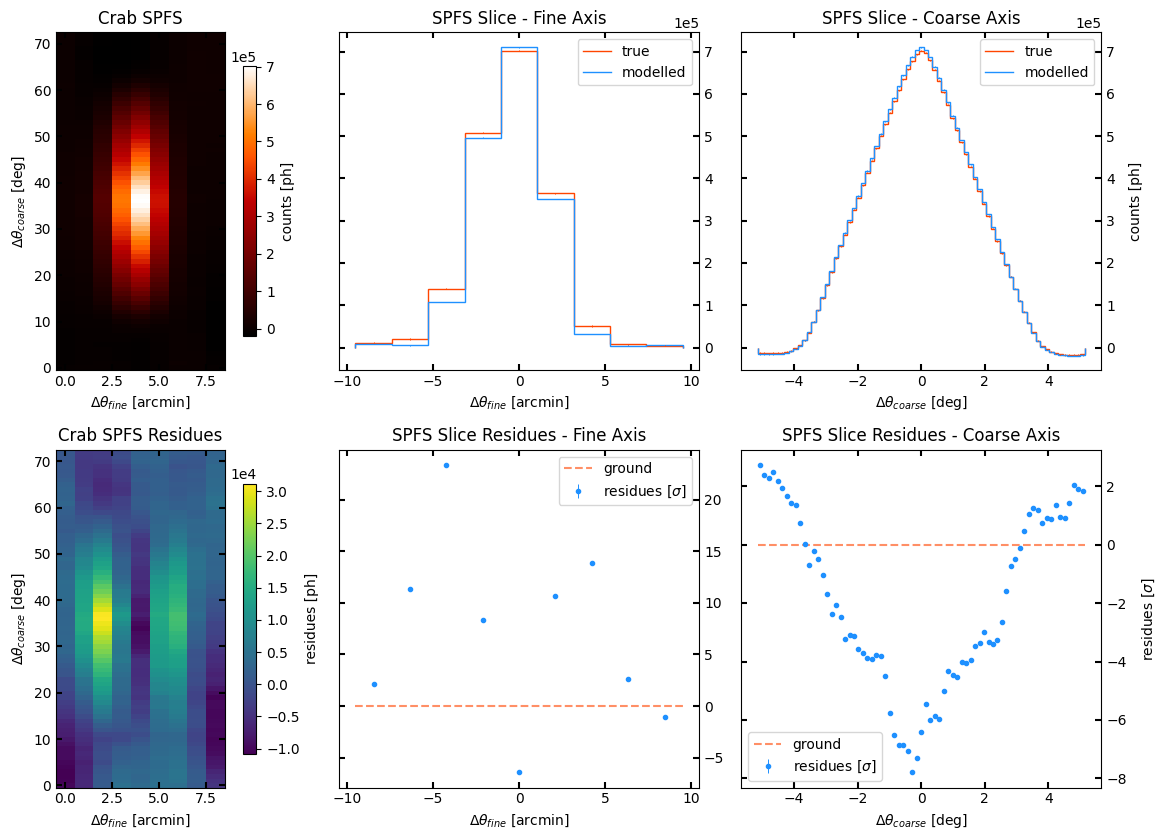

In [26]:
PLOT_MODE: str = 'sigma'

show_SPSF(
    camera=wfm,
    true_w_err=(psf_true, np.sqrt(psf_var)),
    modelled_w_err=(psf_model, np.sqrt(psf_model_var)),
    mode=PLOT_MODE,
    # save_to=f'{OUT_RESULTS_PATH}/Crab_wsigma_{PLOT_MODE}_1ks_{E_min}-{E_max}keV_{ID_CAMERA}.pdf',
    figsize=(4 * 3 + 0.5, 4 * 2 + 0.5),
)